Meteorite Phase 2: RFM Customer Segmentation

In [1]:
import pandas as pd
df = pd.read_csv('../data/Online Retail.csv', encoding='latin1')
df['Revenue'] = df['Quantity'] * df['UnitPrice']
df['InvoiceDate'] = pd.to_datetime(df['InvoiceDate'], format='%Y-%m-%d %H:%M')
df['Cancel_Ordercount'] = df['InvoiceNo'].str.startswith('C', na=True)   
real_orders = df[~df['Cancel_Ordercount']]
real_customer = df[df['CustomerID'].notna()] 
import numpy as np
import matplotlib.pyplot as plt

In [2]:
Date_of_Reference = df['InvoiceDate'].max() + pd.Timedelta(days=1)

In [3]:
Date_of_Reference

Timestamp('2011-12-10 12:50:00')

In [4]:
rfm_base = real_orders[real_orders['CustomerID'].notna()]

In [5]:
rfm_base.nunique()

InvoiceNo            18536
StockCode             3665
Description           3877
Quantity               302
InvoiceDate          17286
UnitPrice              441
CustomerID            4339
Country                 37
Revenue               2940
Cancel_Ordercount        1
dtype: int64

In [6]:
rfm_CID = rfm_base.groupby('CustomerID').agg(
    last_date=('InvoiceDate', 'max'),
    order_count=('InvoiceNo', 'nunique')
)

In [7]:
rfm_CID

,last_date,order_count
CustomerID,,
12346.0,2011-01-18 10:01:00,1
12347.0,2011-12-07 15:52:00,7
12348.0,2011-09-25 13:13:00,4
12349.0,2011-11-21 09:51:00,1
12350.0,2011-02-02 16:01:00,1
...,...,...
18280.0,2011-03-07 09:52:00,1
18281.0,2011-06-12 10:53:00,1
18282.0,2011-12-02 11:43:00,2


In [8]:
Recency = Date_of_Reference - df['InvoiceDate'].max()

In [9]:
rfm_CID['recency'] = Date_of_Reference - rfm_CID['last_date']

In [10]:
rfm_CID['recency']

CustomerID
12346.0   326 days 02:49:00
12347.0     2 days 20:58:00
12348.0    75 days 23:37:00
12349.0    19 days 02:59:00
12350.0   310 days 20:49:00
                 ...       
18280.0   278 days 02:58:00
18281.0   181 days 01:57:00
18282.0     8 days 01:07:00
18283.0     4 days 00:48:00
18287.0    43 days 03:21:00
Name: recency, Length: 4339, dtype: timedelta64[us]

In [11]:
rfm_CID['recency'] = (Date_of_Reference - rfm_CID['last_date']).dt.days

In [12]:
rfm_CID['Monetary'] = real_customer.groupby('CustomerID')['Revenue'].sum()

In [13]:
rfm_m2 = rfm_CID['Monetary'].nlargest()

In [14]:
rfmA = rfm_CID['recency'].groupby(rfm_m2)

In [15]:
rfmA

In [16]:
rfm_CID.loc[14646]


last_date      2011-12-08 12:12:00
order_count                     74
recency                          2
Monetary                 279489.02
Name: 14646.0, dtype: object

In [17]:
rfm_CID.loc[12346] 

last_date      2011-01-18 10:01:00
order_count                      1
recency                        326
Monetary                       0.0
Name: 12346.0, dtype: object

In [18]:
rfm_CID['Monetary'].isna().sum()

np.int64(0)

In [19]:
(rfm_CID['Monetary'] <= 0).sum()

np.int64(17)

In [20]:
rfm_CID['recency']

CustomerID
12346.0    326
12347.0      2
12348.0     75
12349.0     19
12350.0    310
          ... 
18280.0    278
18281.0    181
18282.0      8
18283.0      4
18287.0     43
Name: recency, Length: 4339, dtype: int64

In [21]:
rfm_CID['R_score'] = pd.qcut(rfm_CID['recency'], q=5, labels =[5,4,3,2,1])

In [22]:
rfm_CID['R_score']

CustomerID
12346.0    1
12347.0    5
12348.0    2
12349.0    4
12350.0    1
          ..
18280.0    1
18281.0    1
18282.0    5
18283.0    5
18287.0    3
Name: R_score, Length: 4339, dtype: category
Categories (5, int64): [5 < 4 < 3 < 2 < 1]

In [23]:
rfm_CID['R_score'] = pd.qcut(rfm_CID['recency'], q=5, labels =[5,4,3,2,1]).astype(int) #<-- pandas apparently think 5 is smaller than 4 

In [24]:
rfm_CID['M_score'] = pd.qcut(rfm_CID['Monetary'], q=5, labels =[1,2,3,4,5]).astype(int)

In [25]:
rfm_CID['M_score']

CustomerID
12346.0    1
12347.0    5
12348.0    4
12349.0    4
12350.0    2
          ..
18280.0    1
18281.0    1
18282.0    1
18283.0    5
18287.0    4
Name: M_score, Length: 4339, dtype: int64

In [26]:
print(rfm_CID['R_score'].value_counts())
print(rfm_CID['M_score'].value_counts())
print(rfm_CID.loc[14646])
print(rfm_CID['order_count'].value_counts().sort_index())

R_score
4    905
5    868
1    865
3    858
2    843
Name: count, dtype: int64
M_score
1    868
5    868
4    868
2    868
3    867
Name: count, dtype: int64
last_date      2011-12-08 12:12:00
order_count                     74
recency                          2
Monetary                 279489.02
R_score                          5
M_score                          5
Name: 14646.0, dtype: object
order_count
1      1494
2       835
3       508
4       387
5       243
6       172
7       143
8        98
9        68
10       54
11       52
12       45
13       30
14       20
15       28
16       11
17       18
18       14
19       12
20       12
21       11
22        5
23        5
24        3
25        8
26        7
27        3
28        6
29        1
30        4
31        3
32        3
33        2
34        3
35        1
37        3
38        2
39        2
41        1
44        1
45        1
46        1
47        2
48        1
50        1
51        1
55        2
57        1
60        1
62 

In [27]:
rfm_CID['F_score'] = pd.cut(rfm_CID['order_count'], bins=[0,1,2,4,9,float('inf')], labels=[1,2,3,4,5]).astype(int) #<- lables to bins, 10+ as a separate group to infinity.

In [28]:
rfm_CID['F_score']

CustomerID
12346.0    1
12347.0    4
12348.0    3
12349.0    1
12350.0    1
          ..
18280.0    1
18281.0    1
18282.0    2
18283.0    5
18287.0    3
Name: F_score, Length: 4339, dtype: int64

In [29]:
conditions = [
    (rfm_CID['R_score'] >= 4) & (rfm_CID['F_score'] >= 4),  # Champions
    (rfm_CID['R_score'] == 3) & (rfm_CID['F_score'] >= 4),  # Loyal
    (rfm_CID['R_score'] <= 2) & (rfm_CID['F_score'] >= 3),  # At Risk
    (rfm_CID['R_score'] >= 4) & (rfm_CID['F_score'] <= 2),  # New / Promising
    (rfm_CID['R_score'] <= 2) & (rfm_CID['F_score'] <= 2)   # Lost
]

In [30]:
names = ['Champions', 'Loyal', 'At Risk', 'New / Promising', 'Lost']
rfm_CID['segment'] = np.select(conditions, names, default='Others')

In [31]:
rfm_CID['segment'].value_counts()

segment
Lost               1325
Others             1092
Champions           837
New / Promising     528
At Risk             383
Loyal               174
Name: count, dtype: int64

In [32]:
print("Customer 14646 segment:", rfm_CID.loc[14646, 'segment']) 
print("Customer 12346 segment:", rfm_CID.loc[12346, 'segment'])

Customer 14646 segment: Champions
Customer 12346 segment: Lost


In [33]:
segment_analysis = rfm_CID.groupby('segment').agg(
    customers=('Monetary', 'count'),
    total_monetary=('Monetary', 'sum'),
    avg_monetary=('Monetary', 'mean'),
    avg_recency=('recency', 'mean')
)

In [34]:
segment_analysis['revenue_share'] = segment_analysis['total_monetary'] / rfm_CID['Monetary'].sum()*100

In [35]:
segment_analysis = segment_analysis.sort_values(
    'total_monetary',
    ascending=False
)

In [36]:
segment_analysis['customer_share'] = segment_analysis['customers'] / segment_analysis['customers'].sum() * 100

In [37]:
segment_analysis

,customers,total_monetary,avg_monetary,avg_recency,revenue_share,customer_share
segment,,,,,,
Champions,837,5358984.960,6402.610466,12.365591,64.484685,19.290159
Others,1092,1017263.941,931.560386,39.173993,12.240741,25.167089
Lost,1325,580970.122,438.468017,209.600755,6.990816,30.536990
At Risk,383,565004.181,1475.206739,137.386423,6.798697,8.826919
Loyal,174,525712.830,3021.338103,49.913793,6.325904,4.010141
New / Promising,528,262541.020,497.236780,17.583333,3.159157,12.168702


<Axes: xlabel='segment'>

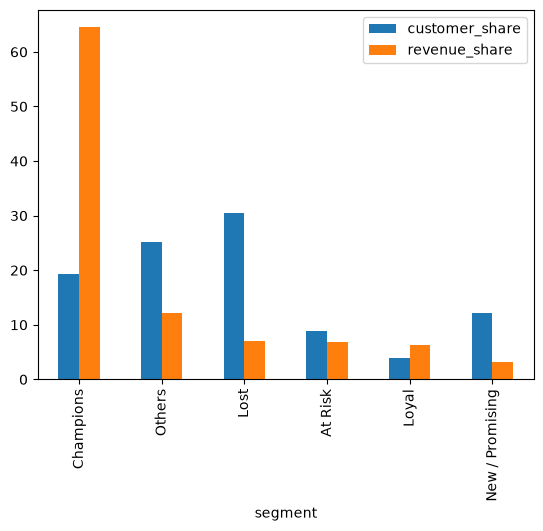

In [38]:
segment_analysis[['customer_share', 'revenue_share']].plot(    kind='bar')

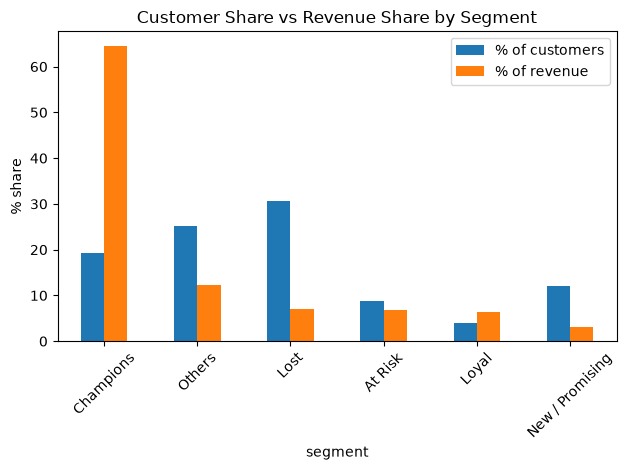

In [39]:
segment_analysis[['customer_share', 'revenue_share']].plot(    kind='bar')
plt.title('Customer Share vs Revenue Share by Segment')
plt.ylabel('% share')
plt.xticks(rotation=45)
plt.legend(['% of customers', '% of revenue'])
plt.tight_layout()
plt.savefig('../charts/rfm_share_by_segment.png') 
plt.show()

In [40]:
at_risk = rfm_CID[rfm_CID['segment'] == 'At Risk']

In [41]:
len(at_risk)

383

In [42]:
at_risk_sort = at_risk.sort_values(
    'Monetary',
    ascending=False
)

In [43]:
at_risk_sort

,last_date,order_count,recency,Monetary,R_score,M_score,F_score,segment
CustomerID,,,,,,,,
15749.0,2011-04-18 13:20:00,3,235,21535.90,1,5,3,At Risk
12409.0,2011-09-22 10:38:00,3,79,11056.93,2,5,3,At Risk
16180.0,2011-08-31 16:28:00,8,100,10217.48,2,5,4,At Risk
13093.0,2011-03-09 12:14:00,8,276,7741.47,1,5,4,At Risk
16745.0,2011-09-14 11:58:00,17,87,7170.70,2,5,5,At Risk
...,...,...,...,...,...,...,...,...
15920.0,2011-07-08 15:31:00,4,154,167.50,2,1,3,At Risk
13003.0,2011-08-26 10:50:00,3,106,149.05,2,1,3,At Risk
13217.0,2011-08-09 15:32:00,3,122,133.62,2,1,3,At Risk


In [44]:
at_risk_sort_t20 = at_risk_sort.head(20)

In [45]:
at_risk_sort_t20['Monetary'].sum() / at_risk_sort['Monetary'].sum() * 100

np.float64(23.44433093672983)

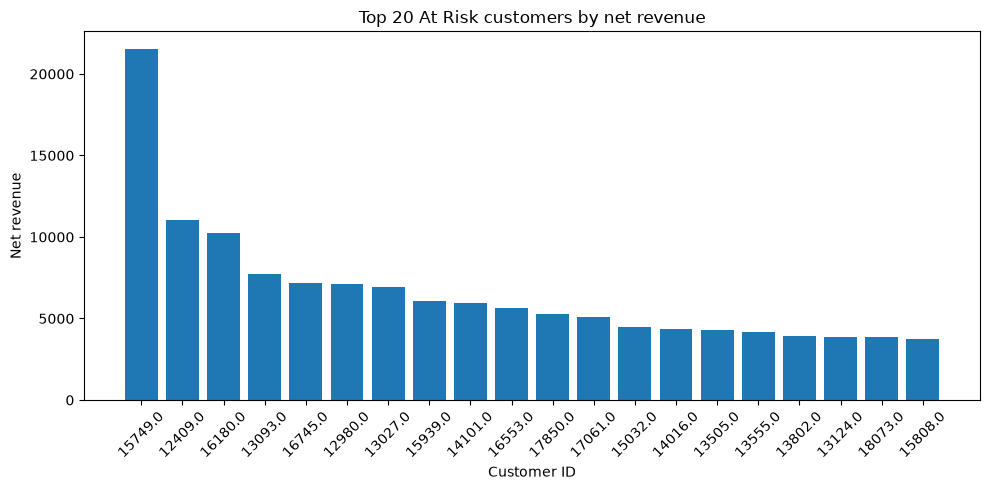

In [46]:
plt.figure(figsize=(10, 5))
categories = at_risk_sort_t20.index.astype(str)
values = at_risk_sort_t20['Monetary']

plt.bar(categories, values)
plt.title('Top 20 At Risk customers by net revenue')
plt.xlabel('Customer ID')
plt.ylabel('Net revenue')
plt.xticks(rotation=45)
plt.tight_layout()

plt.savefig('../charts/rfm_top20_at_risk.png')
plt.show()

Findings and recommendation

Champions are 19% of customers but 64% of revenue. 383 At Risk customers are worth about £565,000, and the top 20 of them hold 23% of that value. Lost customers are the largest group (31%) but bring in only 7% of revenue.

Recommendation: protect the Champions, start retention work with personal outreach to the top 20 At Risk customers, use a cheaper targeted campaign for the other 363, and avoid heavy spending on Lost customers.